# Edition 2: separate synthetic crop experiments

**Interpretation warning:** synthetic scores only describe simulator reconstruction. Real source records keep their published target; no unrelated studies are joined.

## V2 and V3 are simulated; they are not added to the original table
V2: 600 one-time cases per tomato, potato, banana; good/bad from a latent simulator rule. V3: 100 trajectories × 8 observations per crop with generated acceptable/warning/high-risk labels. Real source recordings only anchor some response scales; they are not matched to generated labels or environment.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'artifacts').exists(): ROOT=ROOT.parent
ART=ROOT/'artifacts'
plt.rcParams.update({'figure.figsize':(9,4.5),'axes.spines.top':False,'axes.spines.right':False})
v2=json.loads((ART/'edition2_simulation'/'metrics.json').read_text()); v3=json.loads((ART/'edition2_simulation_v3'/'metrics.json').read_text()); print(v2['interpretation']); print(v2['sensor_note']); print(v3['interpretation'])

Simulator reconstruction only; not measured crop accuracy.
Tomato/banana raw MQ readings are resampled and synthetically perturbed without matching to environment or labels; potato MQ values are fully simulated.
All generated data, labels, and scores are SIMULATION ONLY; not real crop accuracy.


## Five-crop paired-schema V2 (20,000 simulated rows)
This is distinct from the 600-row-per-crop tomato/potato/banana V2 below. Each of its 500 generated lots has one path and 40 times. All sensor, environment and inspection values remain generated.

,input,model,Macro F1,Accuracy,Spoiled recall,Log loss,Brier
0,environment_only,majority,0.206,0.448,1.000,1.064,0.644
1,environment_only,random_forest,0.813,0.815,0.827,0.437,0.263
2,environment_only,xgboost,0.820,0.824,0.845,0.434,0.259
3,mq_only,majority,0.206,0.448,1.000,1.064,0.644
4,mq_only,random_forest,0.786,0.790,0.810,0.501,0.301
5,mq_only,xgboost,0.803,0.808,0.838,0.441,0.271
6,combined,majority,0.206,0.448,1.000,1.064,0.644
7,combined,random_forest,0.829,0.834,0.868,0.424,0.250
8,combined,xgboost,0.834,0.841,0.880,0.386,0.232


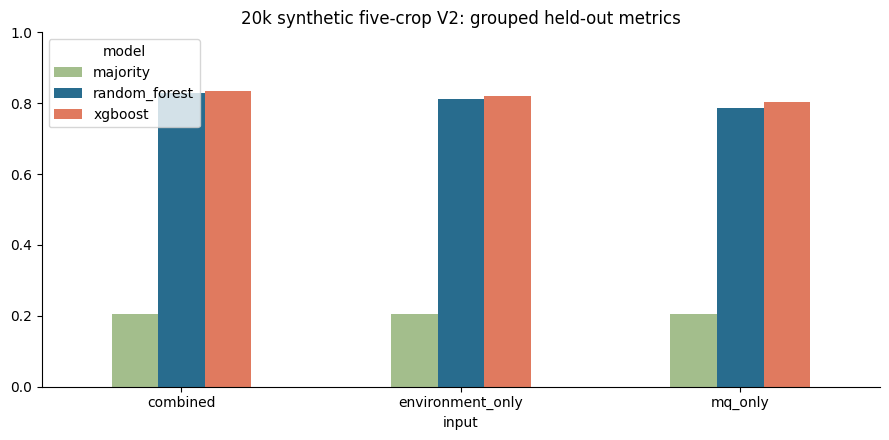

All values are simulator-only; the score tests generated-label reconstruction.


In [2]:
v2five=json.loads((ROOT/'artifacts_v2'/'status_metrics.json').read_text())
fivedf=pd.DataFrame([{"input":r["feature_set"],"model":r["model"],"Macro F1":r["macro_f1"],"Accuracy":r["accuracy"],"Spoiled recall":r["per_class"]["spoiled"]["recall"],"Log loss":r["log_loss"],"Brier":r["multiclass_brier"]} for r in v2five["results"] if not r.get("include_initial_inspection",False)])
display(fivedf.round(3)); fivedf.pivot(index="input",columns="model",values="Macro F1").plot.bar(ylim=(0,1),color=["#a3be8c","#286c8e","#e07a5f"]); plt.title("20k synthetic five-crop V2: grouped held-out metrics"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("All values are simulator-only; the score tests generated-label reconstruction.")

## V2 good/bad results

,rows,good,bad,Macro F1,Bad recall,Accuracy
crop,,,,,,
tomato,600,548,52,0.8208,0.5385,0.9533
potato,600,563,37,0.8595,0.7778,0.9667
banana,600,561,39,0.7003,0.3000,0.9467


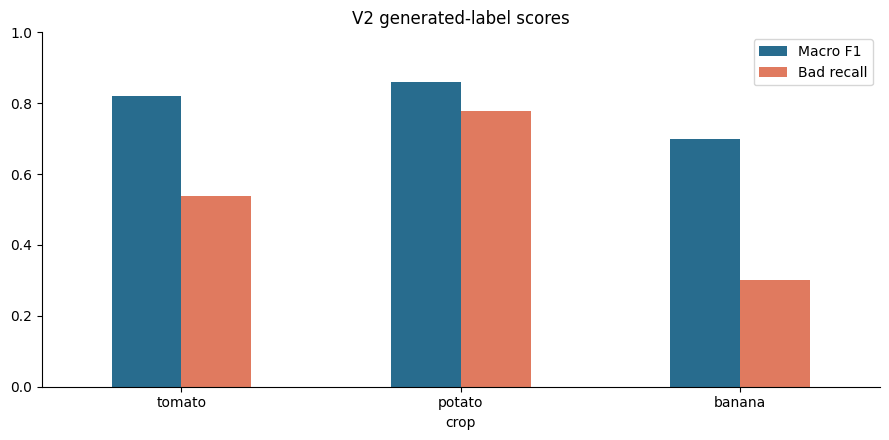

In [3]:
v2df=pd.DataFrame([{'crop':c,'rows':r['rows'],'good':r['synthetic_good'],'bad':r['synthetic_bad'],'Macro F1':r['macro_f1'],'Bad recall':r['bad_recall'],'Accuracy':r['accuracy']} for c,r in v2['models'].items()]).set_index('crop'); display(v2df); v2df[['Macro F1','Bad recall']].plot.bar(ylim=(0,1),color=['#286c8e','#e07a5f']); plt.title('V2 generated-label scores'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## V3 combined-input scores and class counts

,crop,model,Macro F1,High-risk recall,Log loss,Brier
0,tomato,Random Forest,0.787,0.630,0.546,0.318
1,tomato,XGBoost,0.746,0.667,0.468,0.292
2,potato,Random Forest,0.614,0.400,0.684,0.420
3,potato,XGBoost,0.580,0.320,0.712,0.445
4,banana,Random Forest,0.687,0.633,0.614,0.371
5,banana,XGBoost,0.745,0.733,0.578,0.365


,acceptable,warning,high_risk
crop,,,
tomato,393,271,136
potato,380,286,134
banana,368,287,145


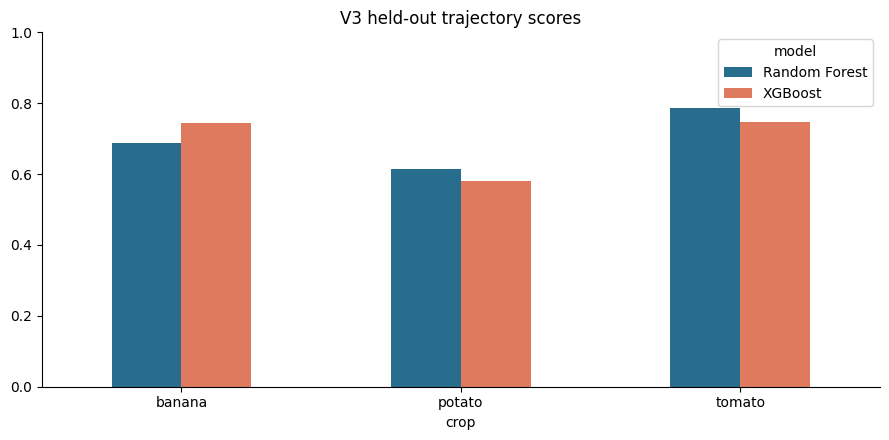

Every V2/V3 score measures generated-label reconstruction, not actual crop quality.


In [4]:
rows=[]; balances=[]
for crop,d in v3['crops'].items():
 balances.append({'crop':crop,**d['class_counts']})
 for name,key in [('Random Forest','combined__random_forest'),('XGBoost','combined__xgboost')]:
  r=d['models'][key]; rows.append({'crop':crop,'model':name,'Macro F1':r['macro_f1'],'High-risk recall':r['class_recall']['high_risk'],'Log loss':r['log_loss'],'Brier':r['multiclass_brier']})
v3df=pd.DataFrame(rows); display(v3df.round(3)); display(pd.DataFrame(balances).set_index('crop')); ax=v3df.pivot(index='crop',columns='model',values='Macro F1').plot.bar(ylim=(0,1),color=['#286c8e','#e07a5f']); ax.set_title('V3 held-out trajectory scores'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print('Every V2/V3 score measures generated-label reconstruction, not actual crop quality.')